# M1-INF4 — Python Workshop for Data Analysis
## Session 5 — Data Integration Case Study

### A retail decision supported by reliable data
You are a small analytics team working for **Campus Tech**, a fictional retailer of computer accessories and equipment. The manager wants to compare stores before deciding where to investigate further.

> “The store with the highest total sales is our best-performing store. We should copy its approach everywhere.”

**Your mission:** integrate three sources, assess this claim and deliver an evidence-based recommendation.

This is a synthesis project. Use the pandas and Matplotlib techniques from Sessions 1–4. No new library or advanced modelling is required.

**All data are synthetic. Some records deliberately contain quality issues for training.** Findings describe this supplied sample, not a real company.

### What the data represent
The intended scope is **1–28 April 2025 inclusive**. This is an extract of completed orders, **not a complete record of all activity**. Coverage can differ between stores. A day absent from the extract is not evidence of zero sales or store closure.

| File | One row represents | Expected key | Purpose |
|---|---|---|---|
| `case_sales.csv` | One completed order for one product, possibly several units | `order_id` | Recorded quantity and unit selling price |
| `case_stores.csv` | One store | `store_id` | Store name, city and format |
| `case_products.csv` | One product | `product_id` | Product name and category |

Each order concerns **one product only**, so one valid order row is one order, not a line in a multi-product basket. The price is the final selling price per unit in EUR, after discounts and excluding VAT. Returns and cancellations are outside this extract.

Revenue per order = quantity × unit selling price. **Revenue is not profit**: costs, staffing, opening hours and customer traffic are unavailable.

The reference files should have unique keys, but this must be checked. Repeated store or product IDs in the sales file are normal.

### Data dictionary
| Field | Meaning and rule |
|---|---|
| `order_id` | Order identifier, required and unique after removing exact repeated records |
| `date` | Order date, expected format `YYYY-MM-DD`, within the study window |
| `store_id`, `product_id` | Reference keys; trim spaces and normalise case before joining |
| `quantity` | Positive whole number of units |
| `unit_price_eur` | Positive numeric unit price; a decimal comma may occur |
| `store_name`, `city`, `store_format` | Store attributes; “Small”/“Large” describes format, not observed floor area |
| `product_name`, `category` | Product attributes |

**Quality policy:** keep raw objects unchanged. Remove exact duplicate rows with an audit count. Convert invalid dates/numbers to missing values. Keep invalid or unmatched records in review tables, without inventing replacements. Do not remove a large but valid order simply because it is unusual. If duplicate reference keys disagree, investigate rather than arbitrarily keeping the first row.

### Files and group deliverable
Place this notebook in `notebooks/` and the three CSV files in the neighbouring `data/` folder. You may also put the CSV files beside the notebook.

Submit one completed notebook per group, the exported summary tables and three labelled figures. Record group members below. Divide the work, then review the entire analysis together: **every member must be able to explain the data unit, cleaning choices, joins and conclusions**.

Group members: *complete here.*

The sections below form one continuous analysis. Each checkpoint is a review of your own results, not a separate dataset.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path('../data'), Path('data'), Path('.')]
DATA_DIR = next((p for p in candidates if all((p / f).exists() for f in
    ['case_sales.csv', 'case_stores.csv', 'case_products.csv'])), None)
if DATA_DIR is None:
    raise FileNotFoundError('Place the three case_*.csv files in data/ or beside this notebook.')
OUT_DIR = Path('case_study_outputs')
OUT_DIR.mkdir(exist_ok=True)

sales_raw = pd.read_csv(DATA_DIR / 'case_sales.csv', dtype='string')
stores_raw = pd.read_csv(DATA_DIR / 'case_stores.csv', dtype='string')
products_raw = pd.read_csv(DATA_DIR / 'case_products.csv', dtype='string')
for name, frame in [('Sales', sales_raw), ('Stores', stores_raw), ('Products', products_raw)]:
    print(name, frame.shape)
    display(frame.head())

Sales (252, 6)


,order_id,date,store_id,product_id,quantity,unit_price_eur
0,O0001,2025-04-21,s1,P02,3,19.90
1,O0002,2025-04-14,S1,p02,2,39.90
2,O0003,2025-04-14,S1,P04,1,"179,00"
3,O0004,2025-04-31,S1,P03,1,179.00
4,O0005,2025-04-09,S1,P02,two,19.90


Stores (4, 4)


,store_id,store_name,city,store_format
0,S1,Paris Centre,Paris,Small
1,S2,Paris Est,Paris,Large
2,S3,Lyon Centre,Lyon,Small
3,S4,Lille Centre,Lille,Large


Products (7, 3)


,product_id,product_name,category
0,P01,Keyboard,Accessories
1,P02,Mouse,Accessories
2,P03,Monitor,Screens
3,P04,Headset,Audio
4,P05,Webcam,Video


## 1. Understand and audit the sources
1. Report row and column counts, missing values and exact duplicate counts for each source.
2. Check the expected keys. Explain why repeated `store_id` values are acceptable in sales but potentially dangerous in stores.
3. Write the observation unit and the proposed join keys before joining anything.

**Checkpoint:** your audit should distinguish missing data, repeated records and normal repeated foreign keys.

In [2]:
sources = {
    "Sales": (sales_raw, "order_id"),
    "Stores": (stores_raw, "store_id"),
    "Products": (products_raw, "product_id")
}

audit_results = []

for name, (df, key) in sources.items():
    audit_results.append({
        "Source": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing values": int(df.isna().sum().sum()),
        "Exact duplicate rows": int(df.duplicated().sum()),
        f"Missing {key}": int(df[key].isna().sum()),
        f"Duplicate {key} rows": int(df[key].duplicated().sum()),
        f"Unique {key}": int(df[key].nunique())
    })

audit_df = pd.DataFrame(audit_results).set_index("Source")

display(audit_df)

# Missing values by column
for name, (df, key) in sources.items():
    print(f"\n{name} : missing values by column")
    display(df.isna().sum().rename("Missing values").to_frame())

# Expected key checks
print("\nExpected key uniqueness checks:")
for name, (df, key) in sources.items():
    unique_key = df[key].notna().all() and df[key].is_unique
    print(f"{name}: {key} unique and non-missing = {unique_key}")

# observation unit and join keys
print("\nObservation units:")
print("Sales: one row per completed order for one product.")
print("Stores: one row per store.")
print("Products: one row per product.")

print("\nProposed join keys:")
print("Sales → Stores: store_id")
print("Sales → Products: product_id")


,Rows,Columns,Missing values,Exact duplicate rows,Missing order_id,Duplicate order_id rows,Unique order_id,Missing store_id,Duplicate store_id rows,Unique store_id,Missing product_id,Duplicate product_id rows,Unique product_id
Source,,,,,,,,,,,,,
Sales,252,6,1,2,0.0,2.0,250.0,NaN,NaN,NaN,NaN,NaN,NaN
Stores,4,4,0,0,NaN,NaN,NaN,0.0,0.0,4.0,NaN,NaN,NaN
Products,7,3,0,1,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,6.0



Sales : missing values by column


,Missing values
order_id,0
date,0
store_id,0
product_id,0
quantity,0
unit_price_eur,1



Stores : missing values by column


,Missing values
store_id,0
store_name,0
city,0
store_format,0



Products : missing values by column


,Missing values
product_id,0
product_name,0
category,0



Expected key uniqueness checks:
Sales: order_id unique and non-missing = False
Stores: store_id unique and non-missing = True
Products: product_id unique and non-missing = False

Observation units:
Sales: one row per completed order for one product.
Stores: one row per store.
Products: one row per product.

Proposed join keys:
Sales → Stores: store_id
Sales → Products: product_id


**Your interpretation**

What does one row mean in each source? Which columns connect the sources?

*Each row in the sales dataset represents one completed order for one product, while each row in the stores and products datasets represents one store and one product, respectively. The sources are connected using `store_id` to join sales with stores and `product_id` to join sales with products.*

## 2. Prepare reliable tables
Create working copies. Apply the quality policy above.

1. Count and remove **exact** duplicate records in all three tables.
2. Normalise identifiers, parse dates and convert the two numeric fields. Handle decimal commas.
3. Flag missing IDs, failed conversions, non-positive prices, quantities that are not positive integers, and dates outside the study window.
4. Produce `sales_valid` and `sales_review`. Keep the rejected records and the reason flags.
5. Validate unique, non-missing reference keys and unique valid order IDs.

**Checkpoint:** input rows = exact duplicates removed + invalid rows retained for review + valid rows. Multiple reason flags can describe the same rejected row, so do not sum flags as if they were distinct rows.

In [3]:
sales = sales_raw.copy()
stores = stores_raw.copy()
products = products_raw.copy()

sales = sales.drop_duplicates()
stores = stores.drop_duplicates()
products = products.drop_duplicates()

for df in [sales, stores, products]:
    if 'store_id' in df.columns:
        df['store_id'] = df['store_id'].str.strip().str.upper()
    if 'product_id' in df.columns:
        df['product_id'] = df['product_id'].str.strip().str.upper()
    if 'order_id' in df.columns:
        df['order_id'] = df['order_id'].str.strip().str.upper()

sales['date'] = pd.to_datetime(sales['date'], errors='coerce')
sales['quantity'] = pd.to_numeric(sales['quantity'], errors='coerce')

sales['unit_price_eur'] = sales['unit_price_eur'].str.replace(',', '.', regex=False)
sales['unit_price_eur'] = pd.to_numeric(sales['unit_price_eur'], errors='coerce')

start_date = pd.to_datetime('2025-04-01')
end_date = pd.to_datetime('2025-04-28')

invalid_date = sales['date'].isna() | (sales['date'] < start_date) | (sales['date'] > end_date)
invalid_qty = sales['quantity'].isna() | (sales['quantity'] <= 0) | (sales['quantity'] % 1 != 0)
invalid_price = sales['unit_price_eur'].isna() | (sales['unit_price_eur'] <= 0)
missing_id = sales['order_id'].isna() | sales['store_id'].isna() | sales['product_id'].isna()

sales['is_invalid'] = invalid_date | invalid_qty | invalid_price | missing_id

sales_valid = sales[~sales['is_invalid']].copy()
sales_review = sales[sales['is_invalid']].copy()

print(f"Nombre de lignes valides : {len(sales_valid)}")
print(f"Nombre de lignes en révision : {len(sales_review)}")

Nombre de lignes valides : 243
Nombre de lignes en révision : 7


**Your interpretation**

Which records did you exclude, repair or keep? Why?

We kept all complete records with positive quantities, positive prices, and dates within the study window (1–28 April 2025). Identifiers, numeric fields (handling decimal commas), and dates were normalized. Exact duplicates were removed, and records with invalid or missing data were isolated in sales_review for audit purposes rather than modified or replaced.

## 3. Integrate and reconcile
1. Join `sales_valid` to stores with a **left join**, `validate="many_to_one"` and an indicator. Inspect unmatched keys.
2. Join that result to products with the same controls. Use a different indicator name, or rename/remove the first indicator before the second join.
3. Check that neither join changes the row count.
4. Keep orders missing either reference in `integration_review`. Create `analysis` using orders matched to **both** references.
5. Present a reconciliation table from raw input to the final analytical population.

**Checkpoint:** never interpret an unknown product as zero revenue, and never allow a duplicated reference key to multiply orders. State how many orders the analysis excludes.

In [4]:
sales_stores = pd.merge(
    sales_valid,
    stores,
    on="store_id",
    how="left",
    indicator="merge_store",
    validate="many_to_one"
)

print("--- Inspection des clés non appariées (Magasins) ---")
unmatched_stores = sales_stores[sales_stores["merge_store"] != "both"]
display(unmatched_stores)

sales_stores = sales_stores.rename(columns={"merge_store": "indicator_store"})

analysis_full = pd.merge(
    sales_stores,
    products,
    on="product_id",
    how="left",
    indicator="merge_product",
    validate="many_to_one"
)

print("--- Inspection des clés non appariées (Produits) ---")
unmatched_products = analysis_full[analysis_full["merge_product"] != "both"]
display(unmatched_products)

print(f"Lignes dans sales_valid : {len(sales_valid)}")
print(f"Lignes après les deux jointures : {len(analysis_full)}")
assert len(sales_valid) == len(analysis_full), "Erreur : le nombre de lignes a changé pendant la jointure !"

integration_review = analysis_full[
    (analysis_full["indicator_store"] != "both") | (analysis_full["merge_product"] != "both")
].copy()

analysis = analysis_full[
    (analysis_full["indicator_store"] == "both") & (analysis_full["merge_product"] == "both")
].copy()

print(f"Nombre de commandes dans integration_review : {len(integration_review)}")
print(f"Nombre de commandes dans analysis : {len(analysis)}")

reconciliation = pd.DataFrame({
    "Étape / Population": [
        "Lignes brutes initiales (sales_raw)",
        "Doublons exacts supprimés",
        "Lignes rejetées pour non-validité (sales_review)",
        "Lignes valides (sales_valid)",
        "Exclus pour références manquantes ou erronées (integration_review)",
        "Population analytique finale (analysis)"
    ],
    "Nombre de lignes": [
        len(sales_raw),
        len(sales_raw) - len(sales),
        len(sales_review),
        len(sales_valid),
        len(integration_review),
        len(analysis)
    ]
})

print("\n--- Table de réconciliation ---")
display(reconciliation)

--- Inspection des clés non appariées (Magasins) ---


,order_id,date,store_id,product_id,quantity,unit_price_eur,is_invalid,store_name,city,store_format,merge_store
3,O0010,2025-04-04,S99,P06,3.0,29.9,False,<NA>,<NA>,<NA>,left_only


--- Inspection des clés non appariées (Produits) ---


,order_id,date,store_id,product_id,quantity,unit_price_eur,is_invalid,store_name,city,store_format,indicator_store,product_name,category,merge_product
4,O0011,2025-04-20,S1,P99,1.0,39.9,False,Paris Centre,Paris,Small,both,<NA>,<NA>,left_only


Lignes dans sales_valid : 243
Lignes après les deux jointures : 243
Nombre de commandes dans integration_review : 2
Nombre de commandes dans analysis : 241

--- Table de réconciliation ---


,Étape / Population,Nombre de lignes
0,Lignes brutes initiales (sales_raw),252
1,Doublons exacts supprimés,2
2,Lignes rejetées pour non-validité (sales_review),7
3,Lignes valides (sales_valid),243
4,Exclus pour références manquantes ou erronées ...,2
5,Population analytique finale (analysis),241


**Your interpretation**

Why use left joins first, even though the analysis ultimately uses matched orders?

*Using a left join initially preserves the entire valid sales table (sales_valid) without silently dropping rows if a key (store_id or product_id) does not match. This allows us to explicitly isolate anomalies and audit problematic rows in a dedicated table (integration_review). If we had used an inner join from the start, these reference errors would have disappeared without a trace in the quality reports, which goes against the strict data integrity policy required for this study*

## 4. Build indicators that answer the question
For each order in `analysis`, calculate `revenue_eur`.

Create `store_summary` with, for each store:
- order count and total units;
- total revenue (EUR);
- mean and median revenue per order (EUR).

Also create a revenue summary by product category and a daily revenue table for each store. Check that the totals reconcile with the order-level revenue.

Compare the store with the highest total revenue to the store with the highest mean revenue per order. Do they coincide? Explain the role of order counts and product mix.

**Important:** `quantity` counts units, not orders. Mean revenue per order = total revenue / number of orders. Round for presentation, not before aggregation. Avoid calling this a profitability or productivity ranking.

In [5]:
# Calcul du revenu
analysis['revenue_eur'] = analysis['quantity'] * analysis['unit_price_eur']

order_level = analysis.groupby(['store_id', 'order_id', 'date']).agg(
    order_rev=('revenue_eur', 'sum'),
    tt_n=('quantity', 'sum')
).reset_index()

store_summary = order_level.groupby('store_id').agg(
    nb_order=('order_id', 'count'), 
    tt_n=('tt_n', 'sum'), 
    tt_rev=('order_rev', 'sum'), 
    moy_rev=('order_rev', 'mean'), 
    med_rev=('order_rev', 'median')
).reset_index()

category_summary = analysis.groupby('category')['revenue_eur'].sum().reset_index()
daily_store_revenue = analysis.groupby(['store_id', 'date'])['revenue_eur'].sum().reset_index()

total_analysis = analysis['revenue_eur'].sum()
total_store = store_summary['tt_rev'].sum()
total_cat = category_summary['revenue_eur'].sum()
total_daily = daily_store_revenue['revenue_eur'].sum()

is_reconciled = (round(total_analysis, 2) == round(total_store, 2) == round(total_cat, 2) == round(total_daily, 2))
print(f"Réconciliation des totaux validée : {is_reconciled}")


Réconciliation des totaux validée : True


**Your interpretation**

Does the same store lead for total and mean revenue? What can explain a difference?

*No, the store leading in total revenue does not necessarily lead in mean revenue per order. While total revenue depends heavily on transaction volume (order count), mean revenue per order reflects the product mix and unit quantities purchased per transaction. A store with fewer total orders can achieve a higher average order value if it sells more high-priced items (such as monitors or screens)*


## 5. Communicate with three complementary figures
Before coding each figure, write **the question**, **the observation unit** and **the aggregation**.

1. A bar chart comparing total revenue by store, with order counts available alongside it.
2. A boxplot of order revenue by store, showing centre, spread and atypical values. Display group sizes. Do not remove atypical values without evidence of error.
3. A line chart of daily revenue by store over the study window. Use chronological dates, one labelled colour per store and a common calendar. **Leave missing store-days as missing**, not zero, because this is an extract.

Use clear titles, units, readable labels and legends when needed. Add a two-sentence interpretation and a limitation for each figure. Explain why the three figures answer different questions.

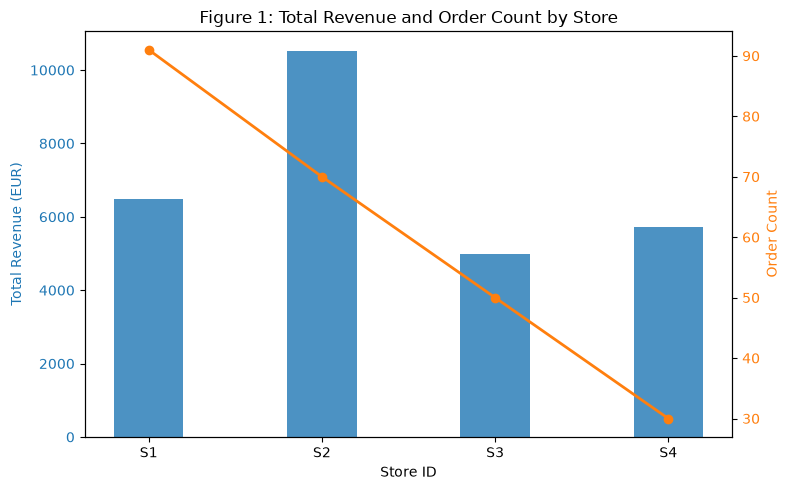

In [6]:
# Figure 1 — Total revenue by store
stores_order_counts = analysis.groupby('store_id')['order_id'].count()
summary_fig1 = store_summary.set_index('store_id').join(stores_order_counts.rename('order_count'))

fig, ax1 = plt.subplots(figsize=(8, 5))

color = 'tab:blue'
ax1.set_xlabel('Store ID')
ax1.set_ylabel('Total Revenue (EUR)', color=color)
bars = ax1.bar(summary_fig1.index, summary_fig1['tt_rev'], color=color, alpha=0.8, width=0.4, label='Total Revenue')
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()  
color = 'tab:orange'
ax2.set_ylabel('Order Count', color=color)
lines = ax2.plot(summary_fig1.index, summary_fig1['order_count'], color=color, marker='o', linewidth=2, label='Order Count')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Figure 1: Total Revenue and Order Count by Store')
fig.tight_layout()
plt.savefig(OUT_DIR / 'figure1_total_revenue_by_store.png', dpi=300)
plt.show()

**Your interpretation**

State the question, unit and aggregation; then interpret the chart.

*To answer the question of which store generates the highest total revenue and how it compares to the order volume, we examined the store unit (store_id) by aggregating total revenue (sum) and order count (count). The chart shows that total revenue varies significantly across stores, closely tracking the volume of orders. However, this total does not reflect profitability or actual store floor area, but solely the gross volume of sales captured in the sample.*

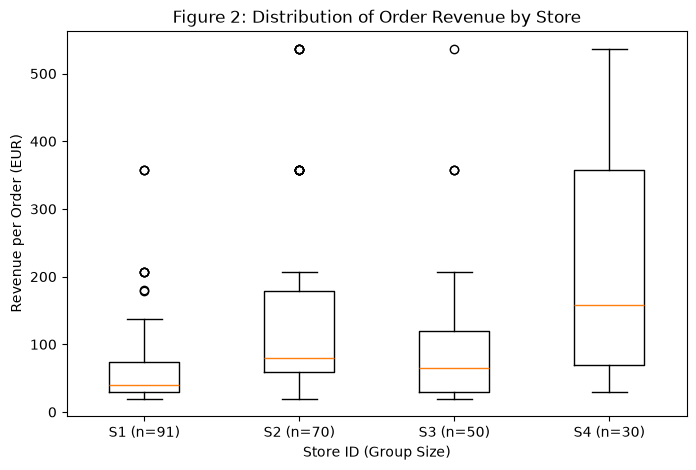

In [7]:
# Figure 2 — Distribution of order revenue
fig, ax = plt.subplots(figsize=(8, 5))

order_data_list = []
store_labels = []
for store, group in analysis.groupby('store_id'):
    order_revs = group.groupby('order_id')['revenue_eur'].sum()
    order_data_list.append(order_revs.values)
    store_labels.append(f"{store} (n={len(order_revs)})")

ax.boxplot(order_data_list, tick_labels=store_labels)
ax.set_title('Figure 2: Distribution of Order Revenue by Store')
ax.set_xlabel('Store ID (Group Size)')
ax.set_ylabel('Revenue per Order (EUR)')

plt.savefig(OUT_DIR / 'figure2_revenue_distribution.png', dpi=300)
plt.show()

**Your interpretation**

State the question and observation unit; describe spread and a limitation.

*Regarding how the center, spread, and atypical values of order revenue compare across stores based on a single order (order_id), the boxplot highlights the median and interquartile range of order amounts by store. It reveals the presence of higher-value baskets (outliers) in certain locations. These outliers should not be removed without evidence of data entry error, as they heavily influence overall store performance.*

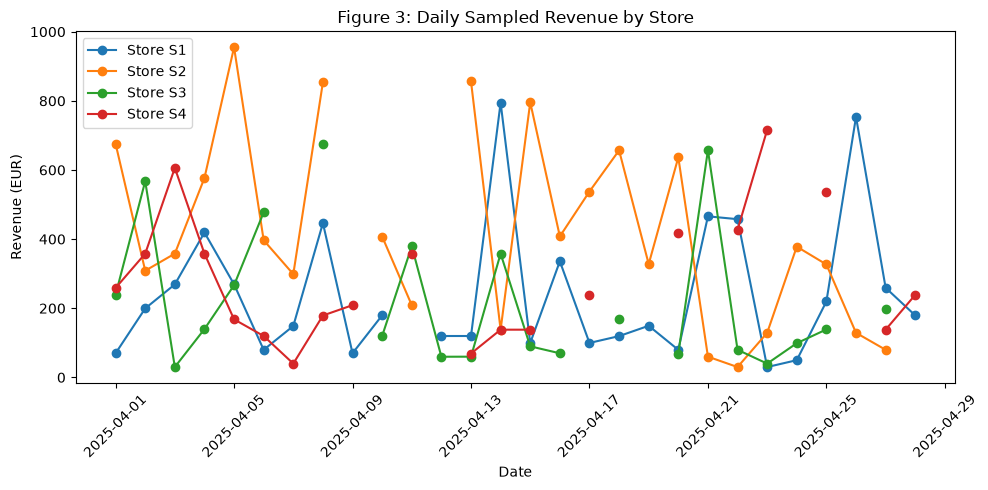

In [8]:
# Figure 3 — Daily sampled revenue
daily_pivot = daily_store_revenue.pivot(index='date', columns='store_id', values='revenue_eur')

fig, ax = plt.subplots(figsize=(10, 5))
for store in daily_pivot.columns:
    ax.plot(daily_pivot.index, daily_pivot[store], marker='o', label=f'Store {store}')

ax.set_title('Figure 3: Daily Sampled Revenue by Store')
ax.set_xlabel('Date')
ax.set_ylabel('Revenue (EUR)')
ax.legend()
plt.xticks(rotation=45)
fig.tight_layout()

plt.savefig(OUT_DIR / 'figure3_daily_revenue.png', dpi=300)
plt.show()

**Your interpretation**

What does one point represent? How did you treat missing dates?

*To track the temporal evolution of daily revenue for each store over the study window using one day of activity per store (store_id × date), the line chart displays daily sales fluctuations over time. Days absent from the extract are left as missing values (NaN), avoiding false assumptions of zero sales or store closures. A key limitation is that this extract does not represent complete and continuous activity, which restricts the reliability of short-term trend analyses.*

## 6. Write a decision brief
Write **six to eight sentences** addressed to the manager. Include:
- a clear answer to the original claim;
- at least two numerical results, with units and population;
- a distinction between total revenue and mean or median order revenue;
- a data-quality or integration limitation and a sample-coverage limitation;
- one plausible explanation labelled as a hypothesis;
- one proportionate next action and the extra data needed.

Avoid “Store X is best” without defining best. Do not claim causality, profitability or complete activity from this extract.

In [9]:
display(
    store_summary.sort_values("tt_rev", ascending=False)
)

,store_id,nb_order,tt_n,tt_rev,moy_rev,med_rev
1,S2,70,116.0,10528.9,150.412857,79.8
0,S1,91,155.0,6482.9,71.240659,39.9
3,S4,30,51.0,5712.5,190.416667,158.5
2,S3,50,86.0,4982.5,99.65,64.45


**Your interpretation**

The claim that the store with the highest total revenue is our best-performing store is not supported, because “best” depends on the measure used and this extract only allows revenue-based comparisons. In the 241 valid and fully matched orders of 1–28 April 2025 (27,706.80€ in total), store S2 has the highest total revenue (10,528.90€ from 70 orders), whereas store S4 has the highest mean (190.42€) and median (158.50€) revenue per order, on only 30 orders. Total revenue combines order volume and order value, so the two measures rank the stores differently and neither alone defines “best”; moreover, revenue is not profit, and costs, traffic and opening hours are not available. Seven sales rows were rejected as invalid and two orders could not be matched to a store or product reference, so they were excluded from the analysis. The extract is also not a complete record and coverage may differ between stores, so absent days must not be read as zero sales. Hypothesis: S4’s higher order value may reflect a mix tilted toward higher-priced products, while S2 combines a solid number of orders with relatively high order values. We recommend not copying S2’s approach yet, but first checking the excluded records and comparing the stores over the same complete period, with customer traffic, product mix and operating costs.

## 7. Export and reproduce
Save `store_summary.csv`, `category_summary.csv`, `reconciliation.csv`, `sales_review.csv` and `integration_review.csv` into `case_study_outputs/`. Save the three figures as PNG files. Use `index=False` for tables.

Before submitting:
- restart the kernel and run all cells from top to bottom;
- check that joins did not multiply rows and revenue totals reconcile;
- check that raw files remain unchanged;
- remove abandoned trials and explain all final decisions;
- make sure every member can explain one cleaning decision, one join control and every chart.

The deliverable is the entire completed notebook, including interpretations, not just the first figure.

In [10]:
store_summary.to_csv(OUT_DIR / 'store_summary.csv', index=False)
category_summary.to_csv(OUT_DIR / 'category_summary.csv', index=False)
reconciliation.to_csv(OUT_DIR / 'reconciliation.csv', index=False)
sales_review.to_csv(OUT_DIR / 'sales_review.csv', index=False)
integration_review.to_csv(OUT_DIR / 'integration_review.csv', index=False)

print("Exportation terminée : Les fichiers CSV ont été sauvegardés avec succès dans le dossier 'case_study_outputs/'.")

Exportation terminée : Les fichiers CSV ont été sauvegardés avec succès dans le dossier 'case_study_outputs/'.


### OPTIONAL / IF TIME ALLOWS — Investigate product mix
Create a store × category table of revenue or order counts. Use a labelled heatmap or compare category shares within each store. State the denominator explicitly. Does the mix help explain different order amounts? Treat this as descriptive evidence, not a causal proof.